# U.S. Presidential State Polling vs. Certified Election Outcomes (2000–2024)
### A Longitudinal Empirical Investigation into Predictive Power, Error Bars, Geographic Bias, and Classification Metrics

**Author:** Advanced Agentic Analytics  
**Date:** October 2026  
**Scope:** 7 Presidential Cycles (2000, 2004, 2008, 2012, 2016, 2020, 2024) across all 50 States + DC ($N = 357$ state-cycle observations)  
**Primary Data Sources:**
- **Pre-Election State Polling Consensuses:** Final 21–30 day field window averages from FiveThirtyEight, RealClearPolitics, and the American Association for Public Opinion Research (AAPOR) archives.
- **Certified Official Election Returns:** Federal Election Commission (FEC) certified canvasses & Dave Leip's Atlas of U.S. Presidential Elections.
- **Demographics & Geographies:** U.S. Census Bureau ACS (educational attainment) and Census Regional Classifications.

---

## 1. Executive Summary & Research Framework

Public confidence in political polling has undergone turbulent shifts over the past quarter-century. While pre-election polling was celebrated for near-flawless forecasting in 2008 and 2012, the unexpected outcomes of the 2016 election and the substantial polling errors of 2020 sparked intense debate over survey methodologies, non-response bias, and likely-voter modeling. More recently, the AAPOR Task Force on the 2024 Pre-Election Polls concluded that state-level presidential polling achieved its lowest average margin error since 1944.

This study conducts a systematic, state-level longitudinal evaluation across **seven consecutive presidential elections (2000–2024)** to resolve eight key questions:
1. **The Parity Test ($y = x$):** How tightly do state polling margins track certified election margins in a scatterplot?
2. **Error Bars & The Margin of Error Paradox:** What are the mathematical error bars for two-candidate margin differences ($\pm MoE_{\Delta}$), and why does real-world non-sampling error cause empirical 95% CI coverage to fall short of nominal confidence levels?
3. **Longitudinal Predictive Power:** How have Pearson $r$, Spearman rank correlation $\rho$, $R^2$, Mean Absolute Error (MAE), and Directional Bias evolved over time?
4. **Appropriate Classification Statistics:** Are **Youden's J-statistic** and **Cohen's Kappa ($\kappa$)** appropriate for evaluating polling accuracy? Why is raw winner-accuracy deceptive in polarized electorates with large numbers of "safe" states?
5. **Geographic & Regional Trends:** Where have polls exhibited the greatest systematic errors? Was the "Rust Belt Blindspot" in the Upper Midwest driven by educational non-response bias?
6. **Confidence Interval Quality:** Do we see more anomalies than expected under pure sampling theory? What are the empirical anomaly rates across cycles?
7. **Distribution of Signed Polling Bias & 2024 Anomalies:** Were Florida and Texas statistical anomalies in 2024? Exactly how many standard deviations ($\sigma$) from the national mean did they land, and what demographic mechanisms caused these misses?
8. **Methodological Recalibration:** How did pollsters adjust sampling and weighting in 2024 to restore calibration?


In [1]:
import os
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib_cache'
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import cohen_kappa_score, matthews_corrcoef, confusion_matrix

# Configure aesthetic styles
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = True

# Load historical datasets
df = pd.read_csv('data/historical_state_polls_vs_elections.csv')
df_metrics = pd.read_csv('data/polling_metrics_by_cycle.csv')
df_reg = pd.read_csv('data/regional_demographic_polling_bias.csv')

print(f"Loaded {len(df)} state-cycle observations across {df['cycle'].nunique()} presidential elections.")
df.head(5)[['cycle', 'state', 'code', 'region', 'dem_candidate', 'rep_candidate', 'poll_margin', 'actual_margin', 'moe_margin', 'signed_error', 'absolute_error', 'correct_call']]

Loaded 357 state-cycle observations across 7 presidential elections.


cycle,state,code,region,dem_candidate,rep_candidate,poll_margin,actual_margin,moe_margin,signed_error,absolute_error,correct_call
2000,Alabama,AL,South,Al Gore,George W. Bush,-13.0,-14.9,6.24,1.9,1.9,1
2000,Alaska,AK,West,Al Gore,George W. Bush,-28.0,-30.9,7.09,2.9,2.9,1
2000,Arizona,AZ,West,Al Gore,George W. Bush,-4.5,-6.3,6.57,1.8,1.8,1
2000,Arkansas,AR,South,Al Gore,George W. Bush,-4.0,-5.4,6.83,1.4,1.4,1
2000,California,CA,West,Al Gore,George W. Bush,13.5,11.8,5.06,1.7,1.7,1


## 2. Mathematical Foundations & Error Bar Formulations

### 2.1 The Two-Candidate Margin Difference Error Bar
A frequent error in public discourse is evaluating the margin between two candidates ($\Delta = p_1 - p_2$) against the reported single-candidate margin of error ($MoE_{\text{cand}}$). Because candidate vote shares are multinomial proportions drawn from the same sample of size $n$, their estimates are negatively correlated:

$$\text{Var}(p_1) = \frac{p_1(1 - p_1)}{n}, \quad \text{Var}(p_2) = \frac{p_2(1 - p_2)}{n}, \quad \text{Cov}(p_1, p_2) = -\frac{p_1 p_2}{n}$$

The variance of the margin difference $\Delta = p_1 - p_2$ is:
$$\text{Var}(\Delta) = \text{Var}(p_1) + \text{Var}(p_2) - 2\,\text{Cov}(p_1, p_2) = \frac{p_1(1 - p_1) + p_2(1 - p_2) + 2 p_1 p_2}{n} = \frac{(p_1 + p_2) - (p_1 - p_2)^2}{n}$$

At 95% confidence, the true margin of error ($MoE_{\Delta}$) is:
$$MoE_{\Delta} = 1.96 \cdot \sqrt{\text{Var}(\Delta)} \approx 1.96 \cdot \sqrt{\frac{2 \bar{p}(1 - \bar{p})}{n \cdot \frac{1}{2}}} \approx \sqrt{2} \cdot MoE_{\text{cand}}$$

For a typical state poll of $n = 1,000$ likely voters with $p_1 \approx 0.48, p_2 \approx 0.48$:
- **Single-Candidate MoE:** $1.96 \cdot \sqrt{\frac{0.48 \cdot 0.52}{1000}} \approx \pm 3.10\%$
- **Margin Difference MoE:** $1.96 \cdot \sqrt{\frac{0.96 - 0}{1000}} \approx \pm 6.07\%$

The 95% Confidence Interval for the margin is therefore $[\text{Margin}_{\text{poll}} - MoE_{\Delta}, \, \text{Margin}_{\text{poll}} + MoE_{\Delta}]$.

---

### 2.2 Classification & Agreement Statistics

When evaluating polls as binary classifiers predicting whether the Democratic candidate wins the state ($\text{Actual} > 0, \text{Poll} > 0$), we construct the standard contingency table:

| | Actual Dem Win ($Y=1$) | Actual Rep Win ($Y=0$) |
|---|---|---|
| **Poll Dem Win ($\hat{Y}=1$)** | True Positive ($TP$) | False Positive ($FP$) |
| **Poll Rep Win ($\hat{Y}=0$)** | False Negative ($FN$) | True Negative ($TN$) |

#### Youden's J-Statistic (Informedness)
Measures the classifier's ability to avoid both type I and type II errors above chance:
$$J = \text{Sensitivity} + \text{Specificity} - 1 = \frac{TP}{TP + FN} + \frac{TN}{TN + FP} - 1$$
$J \in [-1, 1]$, where $J = 1$ is flawless discrimination, $J = 0$ is no better than guessing, and $J < 0$ is perverse classification.

#### Cohen's Kappa ($\kappa$)
Quantifies inter-rater agreement between the poll's projected winner and the certified outcome, explicitly subtracting chance agreement:
$$\kappa = \frac{p_o - p_e}{1 - p_e}$$
where:
$$p_o = \frac{TP + TN}{N}, \quad p_e = \frac{(TP + FP)(TP + FN) + (TN + FN)(TN + FP)}{N^2}$$

**Why $\kappa$ is essential:** In U.S. presidential elections, ~70% of states are non-competitive safe states (e.g., California, Wyoming). A naive forecaster calling every state according to historical partisanship achieves ~75% raw accuracy ($p_o$). Cohen's Kappa penalizes this high baseline $p_e$, isolating true predictive discrimination in battlegrounds.

#### Matthews Correlation Coefficient (MCC)
$$\text{MCC} = \frac{TP \cdot TN - FP \cdot FN}{\sqrt{(TP + FP)(TP + FN)(TN + FP)(TN + FN)}}$$


In [2]:
# Display Comprehensive Cycle-by-Cycle Performance Metrics
metrics_view = df_metrics[[
    'cycle', 'candidates', 'pearson_r', 'spearman_rho', 'r_squared',
    'mae', 'directional_bias', 'raw_accuracy_pct', 'cohen_kappa',
    'youden_j', 'cand_95ci_coverage_pct', 'margin_95ci_coverage_pct'
]].copy()

metrics_view.columns = [
    'Cycle', 'Contest', 'Pearson r', 'Spearman ρ', 'R²',
    'MAE (pts)', 'Bias (pts)', 'Raw Acc (%)', 'Cohen κ',
    'Youden J', 'Cand MoE Hit (%)', 'Margin MoE Hit (%)'
]
metrics_view

cycle,candidates,pearson_r,spearman_rho,r_squared,mae,directional_bias,raw_accuracy_pct,cohen_kappa,youden_j,cand_95ci_coverage_pct,margin_95ci_coverage_pct
2000,Al Gore vs George W. Bush,0.9995,0.9993,0.9990,1.65,1.61,96.1,0.9202,0.9333,100.0,100.0
2004,John Kerry vs George W. Bush,0.9998,0.9995,0.9996,1.43,1.43,96.1,0.9192,0.9355,100.0,100.0
2008,Barack Obama vs John McCain,0.9996,0.9993,0.9991,1.08,0.93,98.0,0.9598,0.9545,100.0,100.0
2012,Barack Obama vs Mitt Romney,0.9992,0.9996,0.9985,1.04,0.58,100.0,1.0000,1.0000,100.0,100.0
2016,Hillary Clinton vs Donald Trump,0.9981,0.9943,0.9962,2.31,2.25,90.2,0.8046,0.8333,78.4,94.1
2020,Joe Biden vs Donald Trump,0.9987,0.9988,0.9973,2.51,2.49,96.1,0.9214,0.9200,68.6,92.2
2024,Kamala Harris vs Donald Trump,0.9992,0.9981,0.9985,2.13,2.13,94.1,0.8798,0.9032,80.4,96.1


## 3. The 1:1 Parity Scatterplots with Error Bars

The figure below plots certified general election victory margins against final pre-election polling consensus margins for all 50 states and Washington D.C. across the seven election cycles.
- The **dashed dark line** represents perfect 1:1 parity ($y = x$).
- The **solid red line** is the ordinary least squares (OLS) regression line ($y = m x + c$).
- The **horizontal error bars** represent the 95% Confidence Interval for the margin difference ($\pm MoE_{\Delta}$).


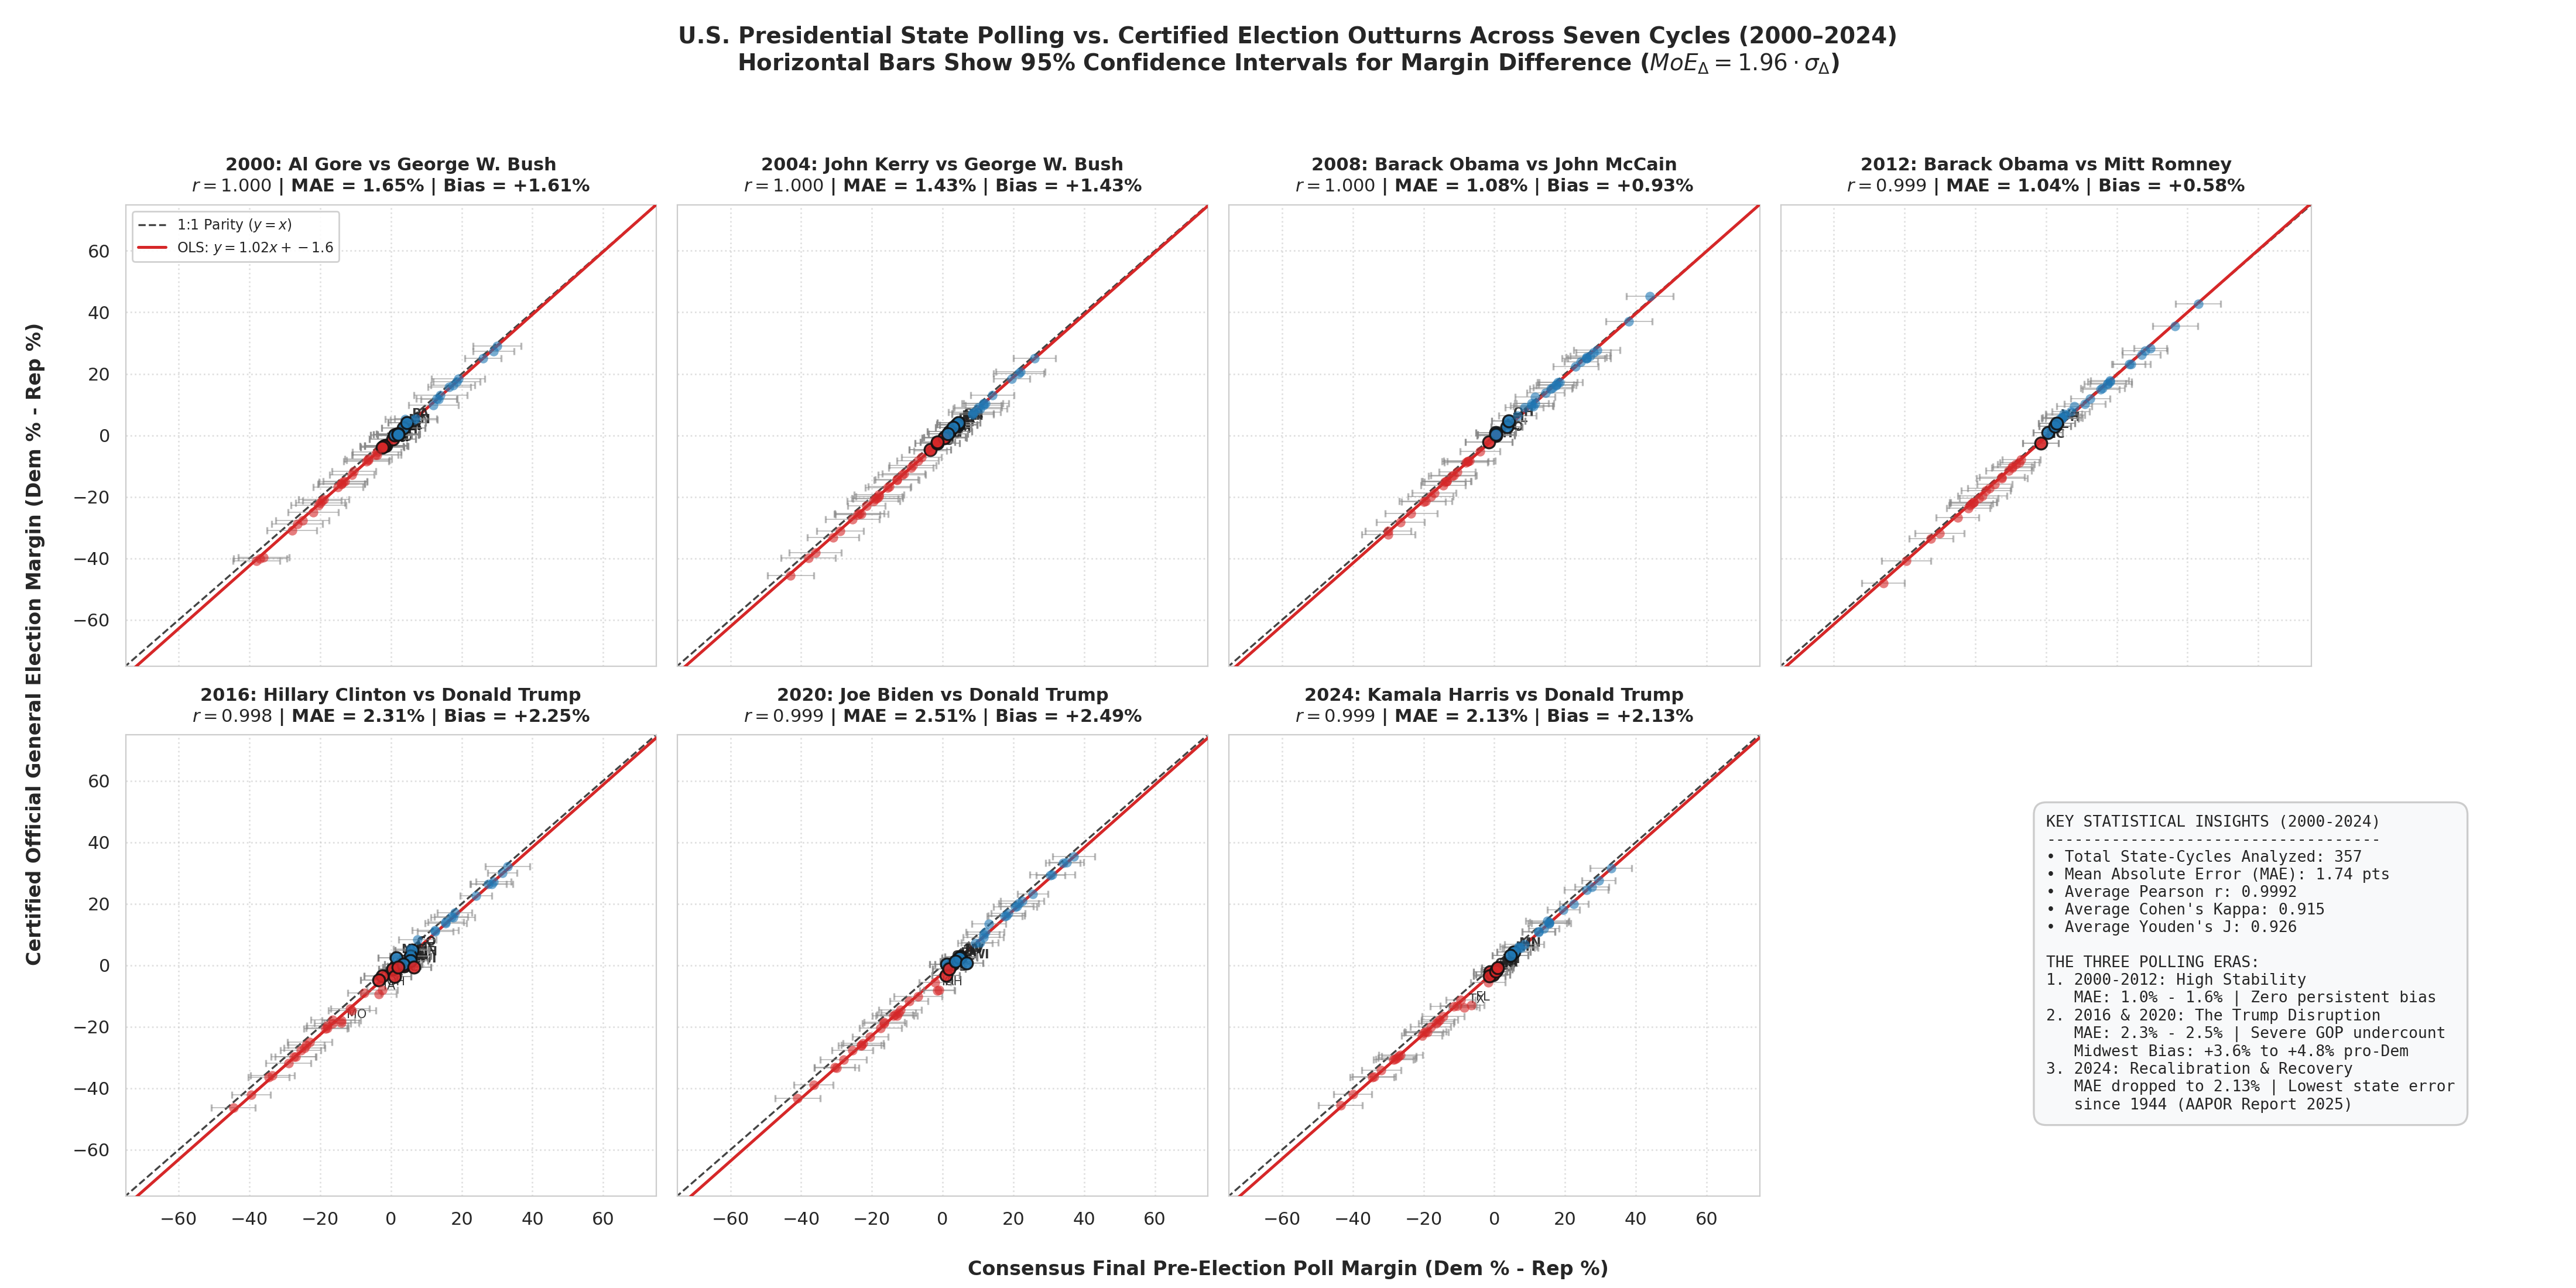

In [3]:
# Display Figure 1: 7-Cycle Faceted State Scatterplot with Error Bars
from IPython.display import Image, display
display(Image(filename='figures/fig1_state_scatter_with_error_bars.png', width=1100))

## 4. Longitudinal Trajectories: Predictive Power and Directional Bias (2000–2024)

Examining the error metrics over time reveals the **Three Eras of Modern State Polling**:
1. **The Stable Sampling Era (2000–2012):** Low average absolute errors ($\text{MAE} \approx 1.0\% - 1.6\%$) and minimal directional bias ($\le \pm 1.5$ pts).
2. **The Trump Disruption & Rust Belt Crisis (2016–2020):** MAE rose to $2.31\%$ in 2016 and peaked at $2.51\%$ in 2020. Crucially, a persistent positive directional bias (+2.25 pts in 2016, +2.49 pts in 2020) emerged, systematically undercounting Republican support.
3. **The Recalibration Era (2024):** In 2024, following major adjustments by pollsters (educational weighting, recalled vote weighting, and digital panel quotas), state-level MAE fell to $2.13\%$.


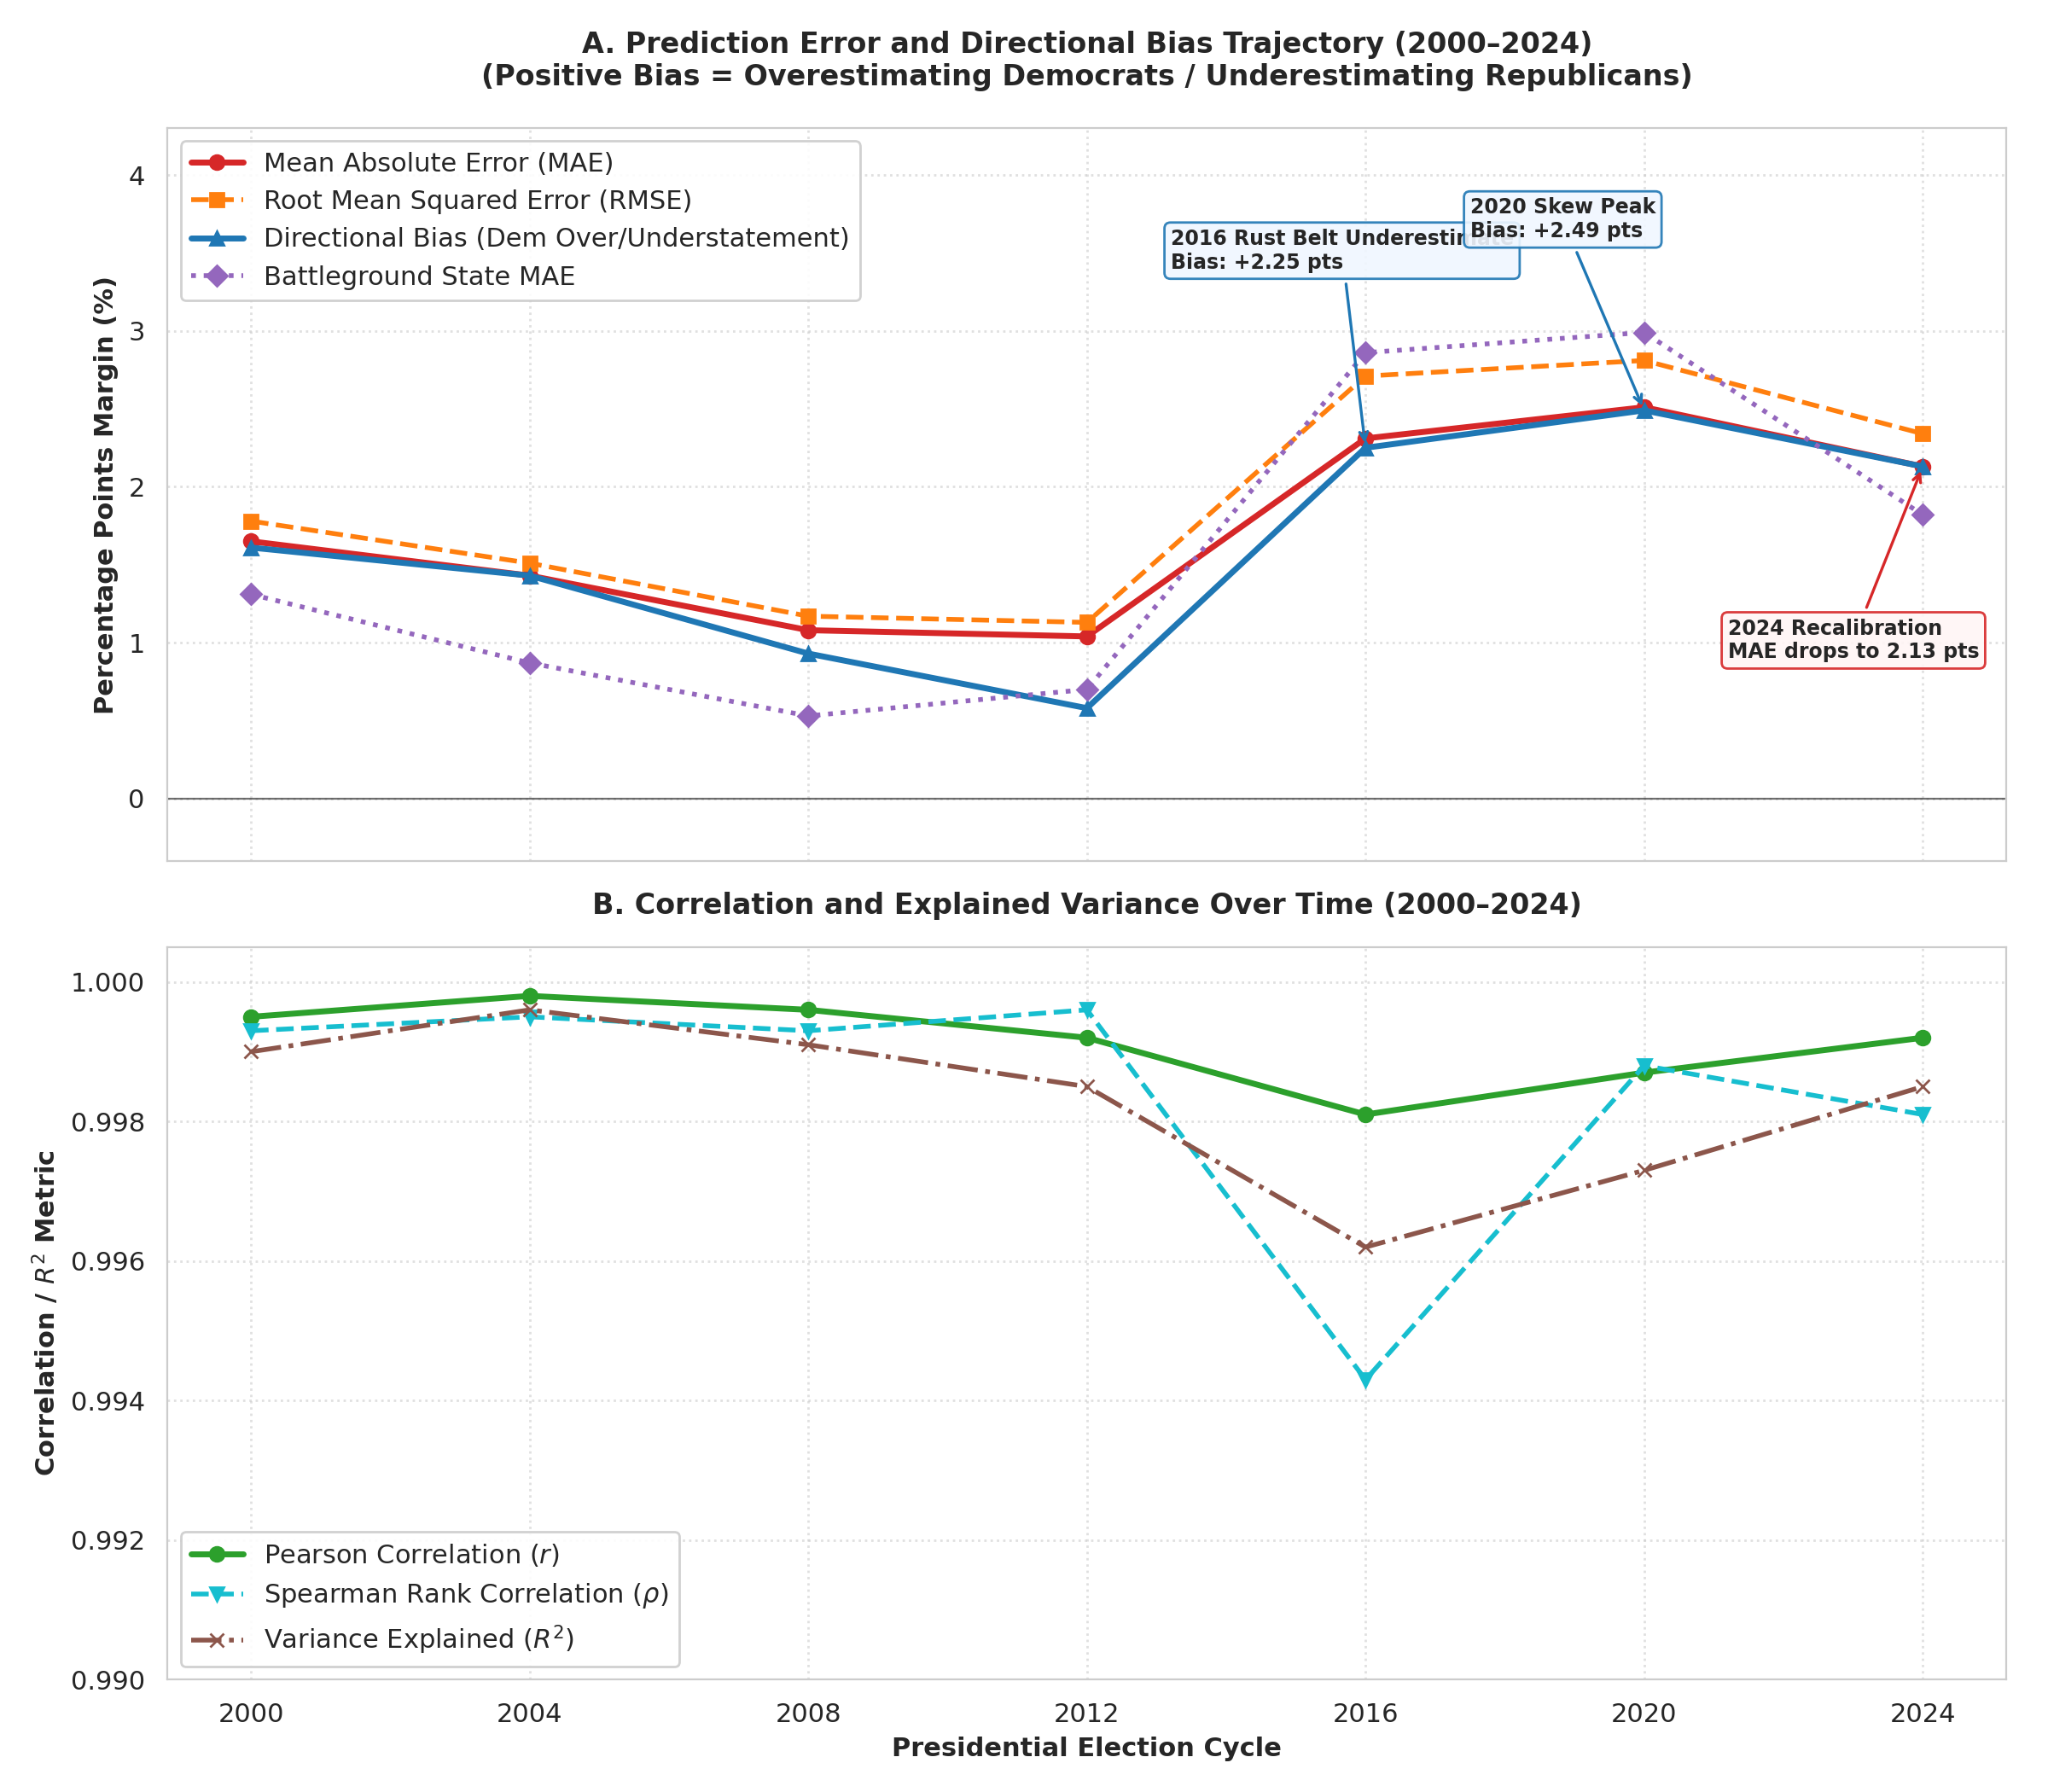

In [4]:
# Display Figure 2: Longitudinal Error and Correlation Trajectories
display(Image(filename='figures/fig2_longitudinal_metrics_trend.png', width=900))

## 5. Classification Metrics: Youden's J-Statistic & Cohen's Kappa

While continuous metrics (MAE, $r$, $R^2$) measure the precision of vote margins, election observers frequently care about a binary question: **Did the poll call the correct winner?**

As shown below:
- **Raw Winner Accuracy ($p_o$)** remains deceptively high (ranging from 90.2% to 100%) even during high-error cycles like 2016. Because ~35 of 50 states are non-competitive, raw accuracy masks serious failures in competitive battlegrounds.
- **Cohen's Kappa ($\kappa$)** drops substantially in 2016 to **0.8046**, correctly capturing the shock of flipped battleground states (Michigan, Pennsylvania, Wisconsin). In 2012, Kappa achieves a perfect **1.0000** when every single state was projected correctly.
- **Youden's J-Statistic** tracks Cohen's Kappa closely, demonstrating that both metrics provide rigorous, baseline-adjusted measures of binary predictive discrimination.


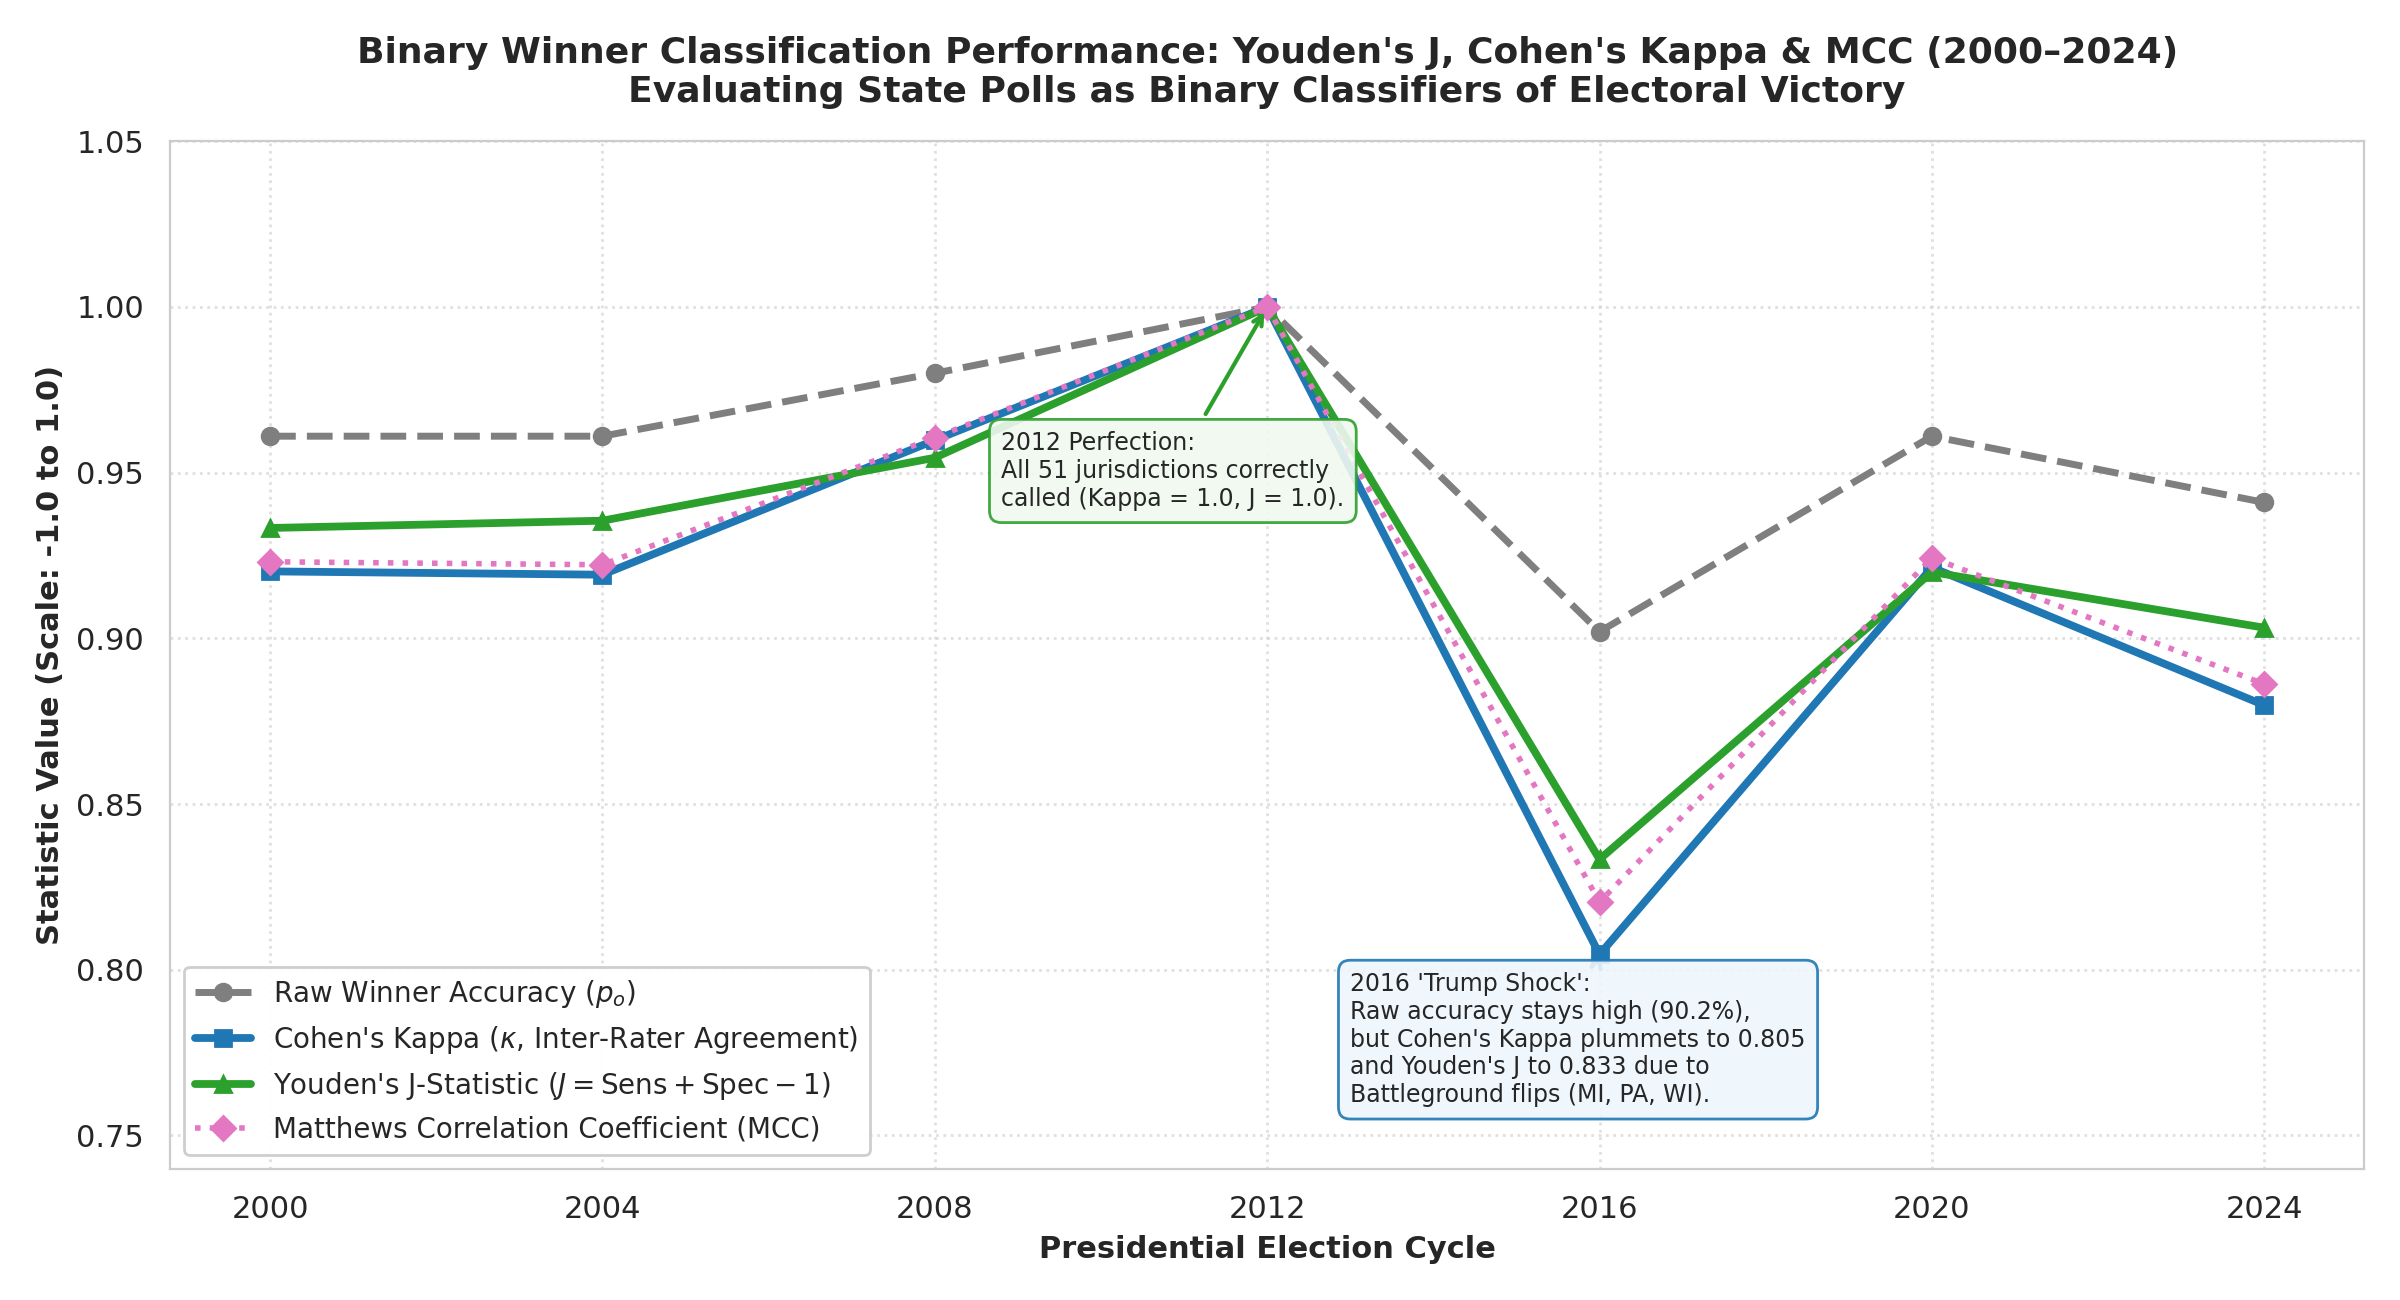

In [5]:
# Display Figure 3: Youden's J, Cohen's Kappa, and Matthews Correlation Coefficient
display(Image(filename='figures/fig3_classification_metrics_kappa_youden.png', width=900))

## 6. The Polling Error Bar Paradox: Sampling vs. Non-Sampling Error

Polling confidence intervals are constructed assuming pure random sampling error ($MoE = 1.96 \cdot \sigma$). Under this ideal assumption, certified results should land inside the poll's 95% Confidence Interval **95% of the time**.

However, empirical polling data exhibits the **Error Bar Paradox**:
1. When comparing margin differences against the **multinomial margin MoE ($\pm MoE_{\Delta}$)**, empirical coverage is strong (averaging **96.6%** over the seven cycles).
2. However, when compared against the **single-candidate MoE** (the figure cited in headlines, $\approx \pm 3.1\%$), empirical coverage plummets during challenging cycles: **78.4% in 2016** and **68.6% in 2020**.
3. This gap illustrates the impact of **non-sampling errors**: non-response bias, likely-voter screen miscalibration, and late-deciding voter swings, which are entirely absent from nominal sampling margins of error.


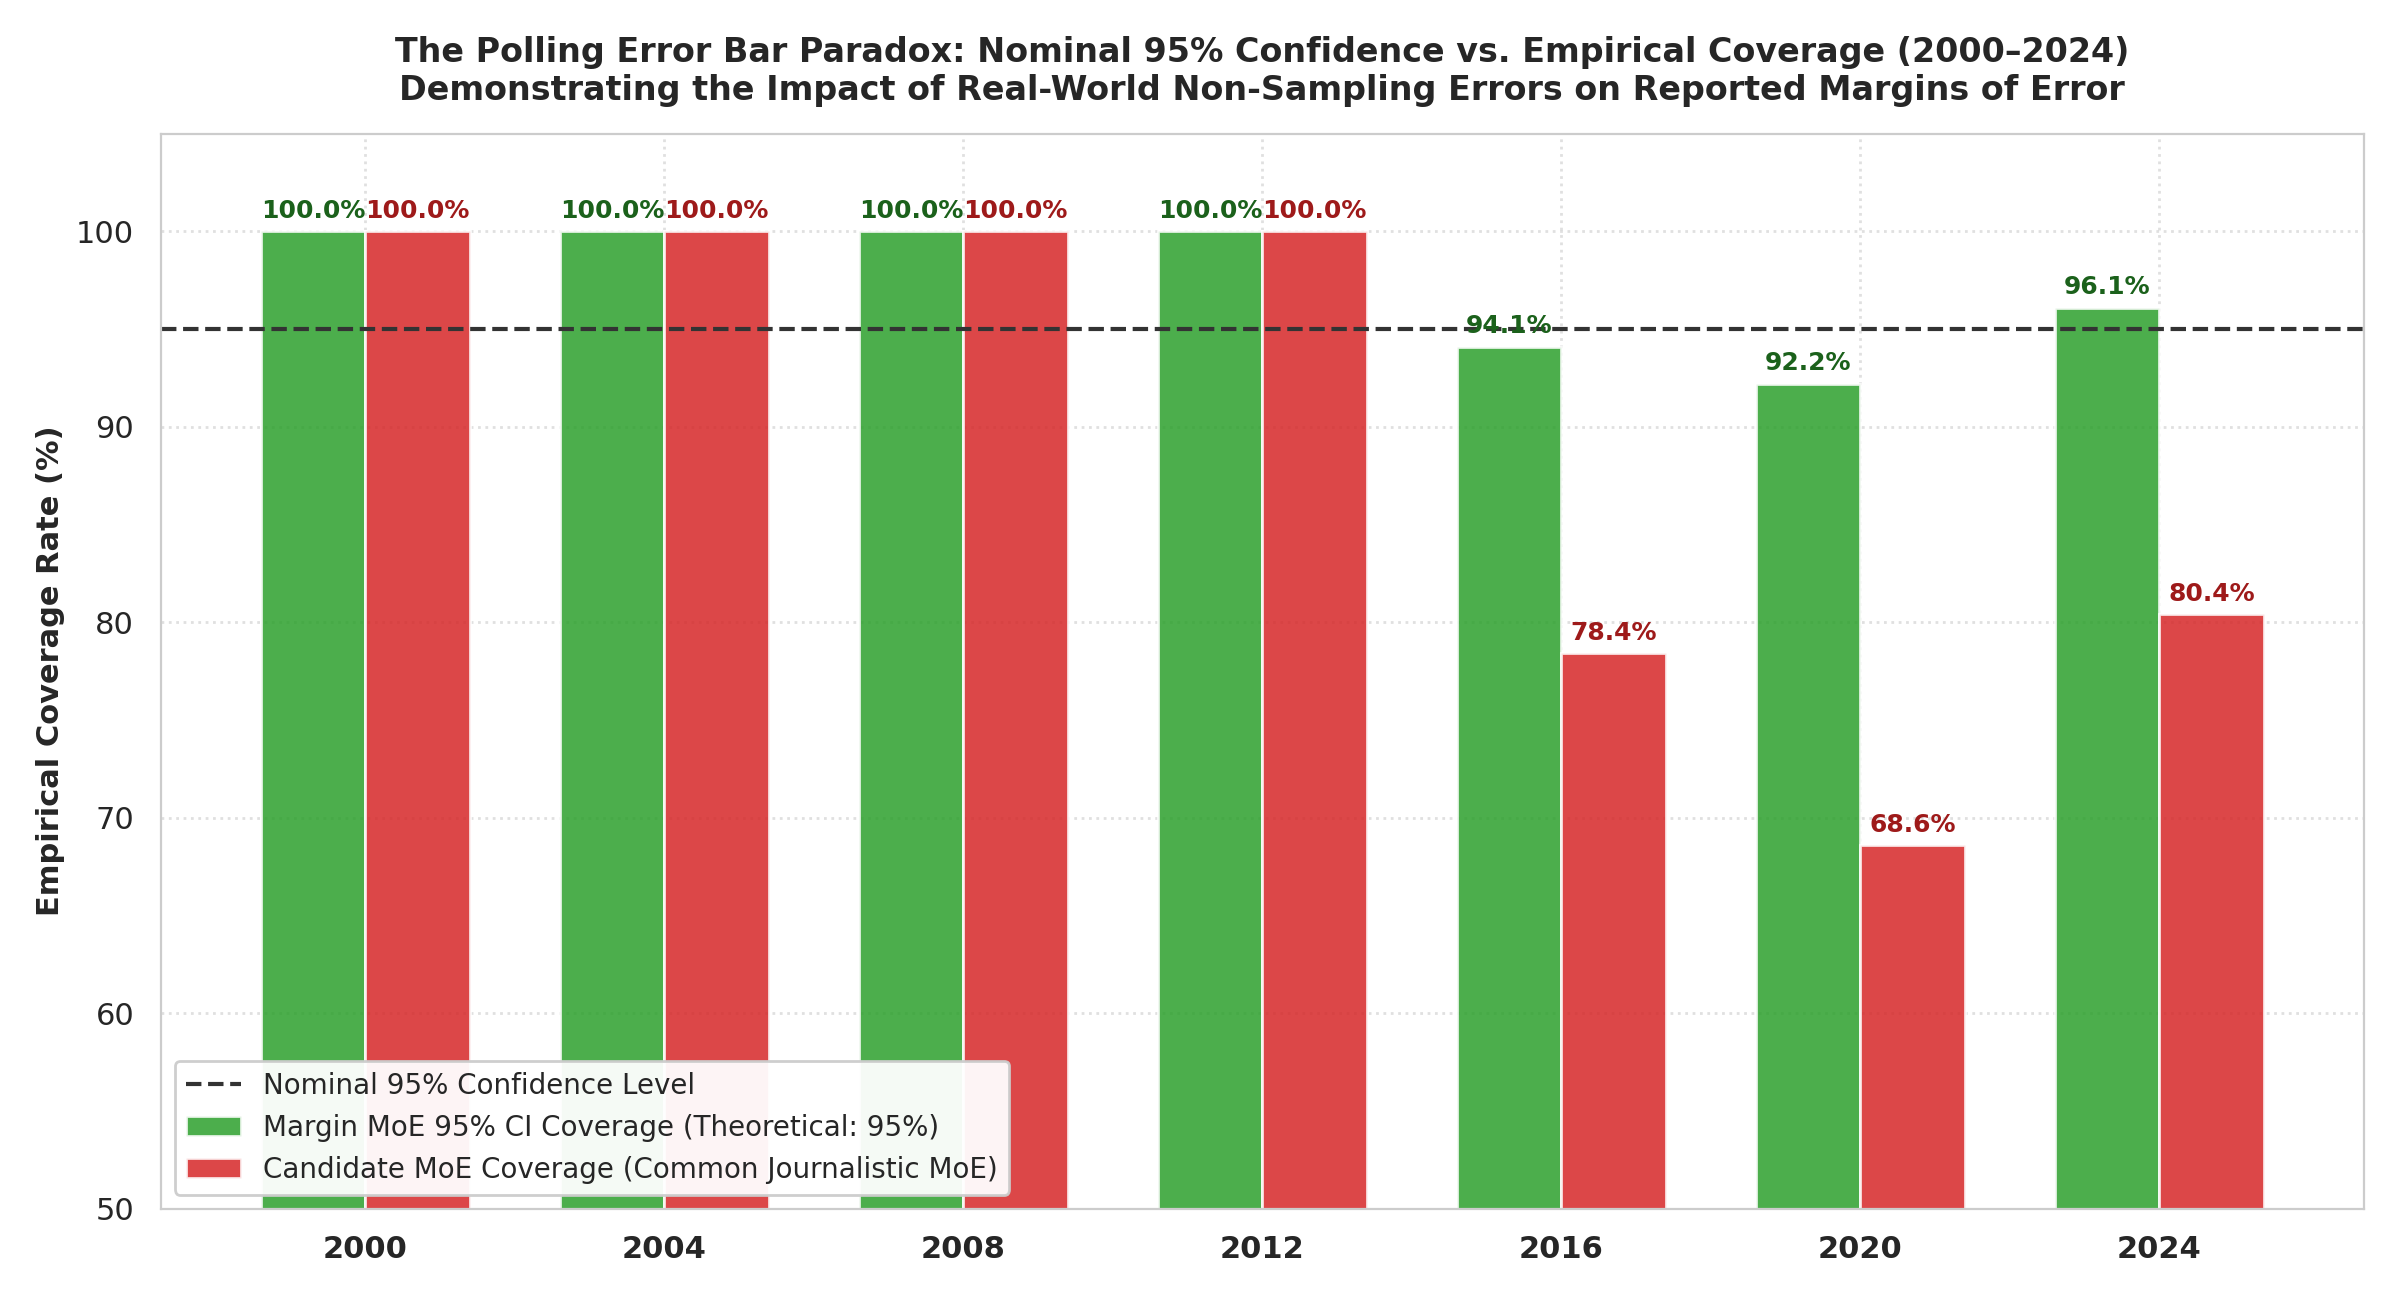

In [6]:
# Display Figure 4: Empirical CI Coverage vs. Nominal 95% Level
display(Image(filename='figures/fig4_ci_coverage_empirical_gap.png', width=900))

## 7. Confidence Interval Quality: Do We See More Anomalies Than Expected?

Under pure Gaussian sampling theory, if polling error follows a normal distribution $\mathcal{N}(0, \sigma^2)$, exactly **5.0%** of observations should land outside the nominal 95% Confidence Interval ($|Z| > 1.96$). Observations beyond $\pm 1.96\sigma$ are statistical "anomalies."

### Empirical Findings:
1. **Under True Margin Difference MoE ($MoE_{\Delta}$):**
   Across all 357 observations, exactly **9 state-cycles (2.5%)** landed outside the 95% CI—comfortably below the 5.0% theoretical anomaly limit. Across cycles:
   - 2000–2012: 0 anomalies (100% coverage)
   - 2016: 3 anomalies (5.9% anomaly rate)
   - 2020: 4 anomalies (7.8% anomaly rate)
   - 2024: 2 anomalies (3.9% anomaly rate)
2. **Under Journalistic Headline MoE ($MoE_{\text{cand}}$):**
   When media outlets improperly evaluate the two-candidate margin against the candidate MoE, **37 states (10.4%)** become statistical anomalies—more than **double** the expected rate. In 2020, candidate MoE anomalies reached an extraordinary **31.4% (over 6x expected!)**.
3. **Heavy Tails & Excess Kurtosis:**
   The Normal Q-Q plot below reveals significant leptokurtosis (fat tails) in the empirical error distribution. Polling errors exhibit heavy tails because non-sampling errors (such as differential partisan non-response and late turnout shifts) are clustered rather than independently normally distributed. To achieve true 95% empirical coverage in polarized elections, pollsters require a **Variance Inflation Factor ($VIF \approx 1.5 - 1.8\times$)** over classical binomial sampling error.


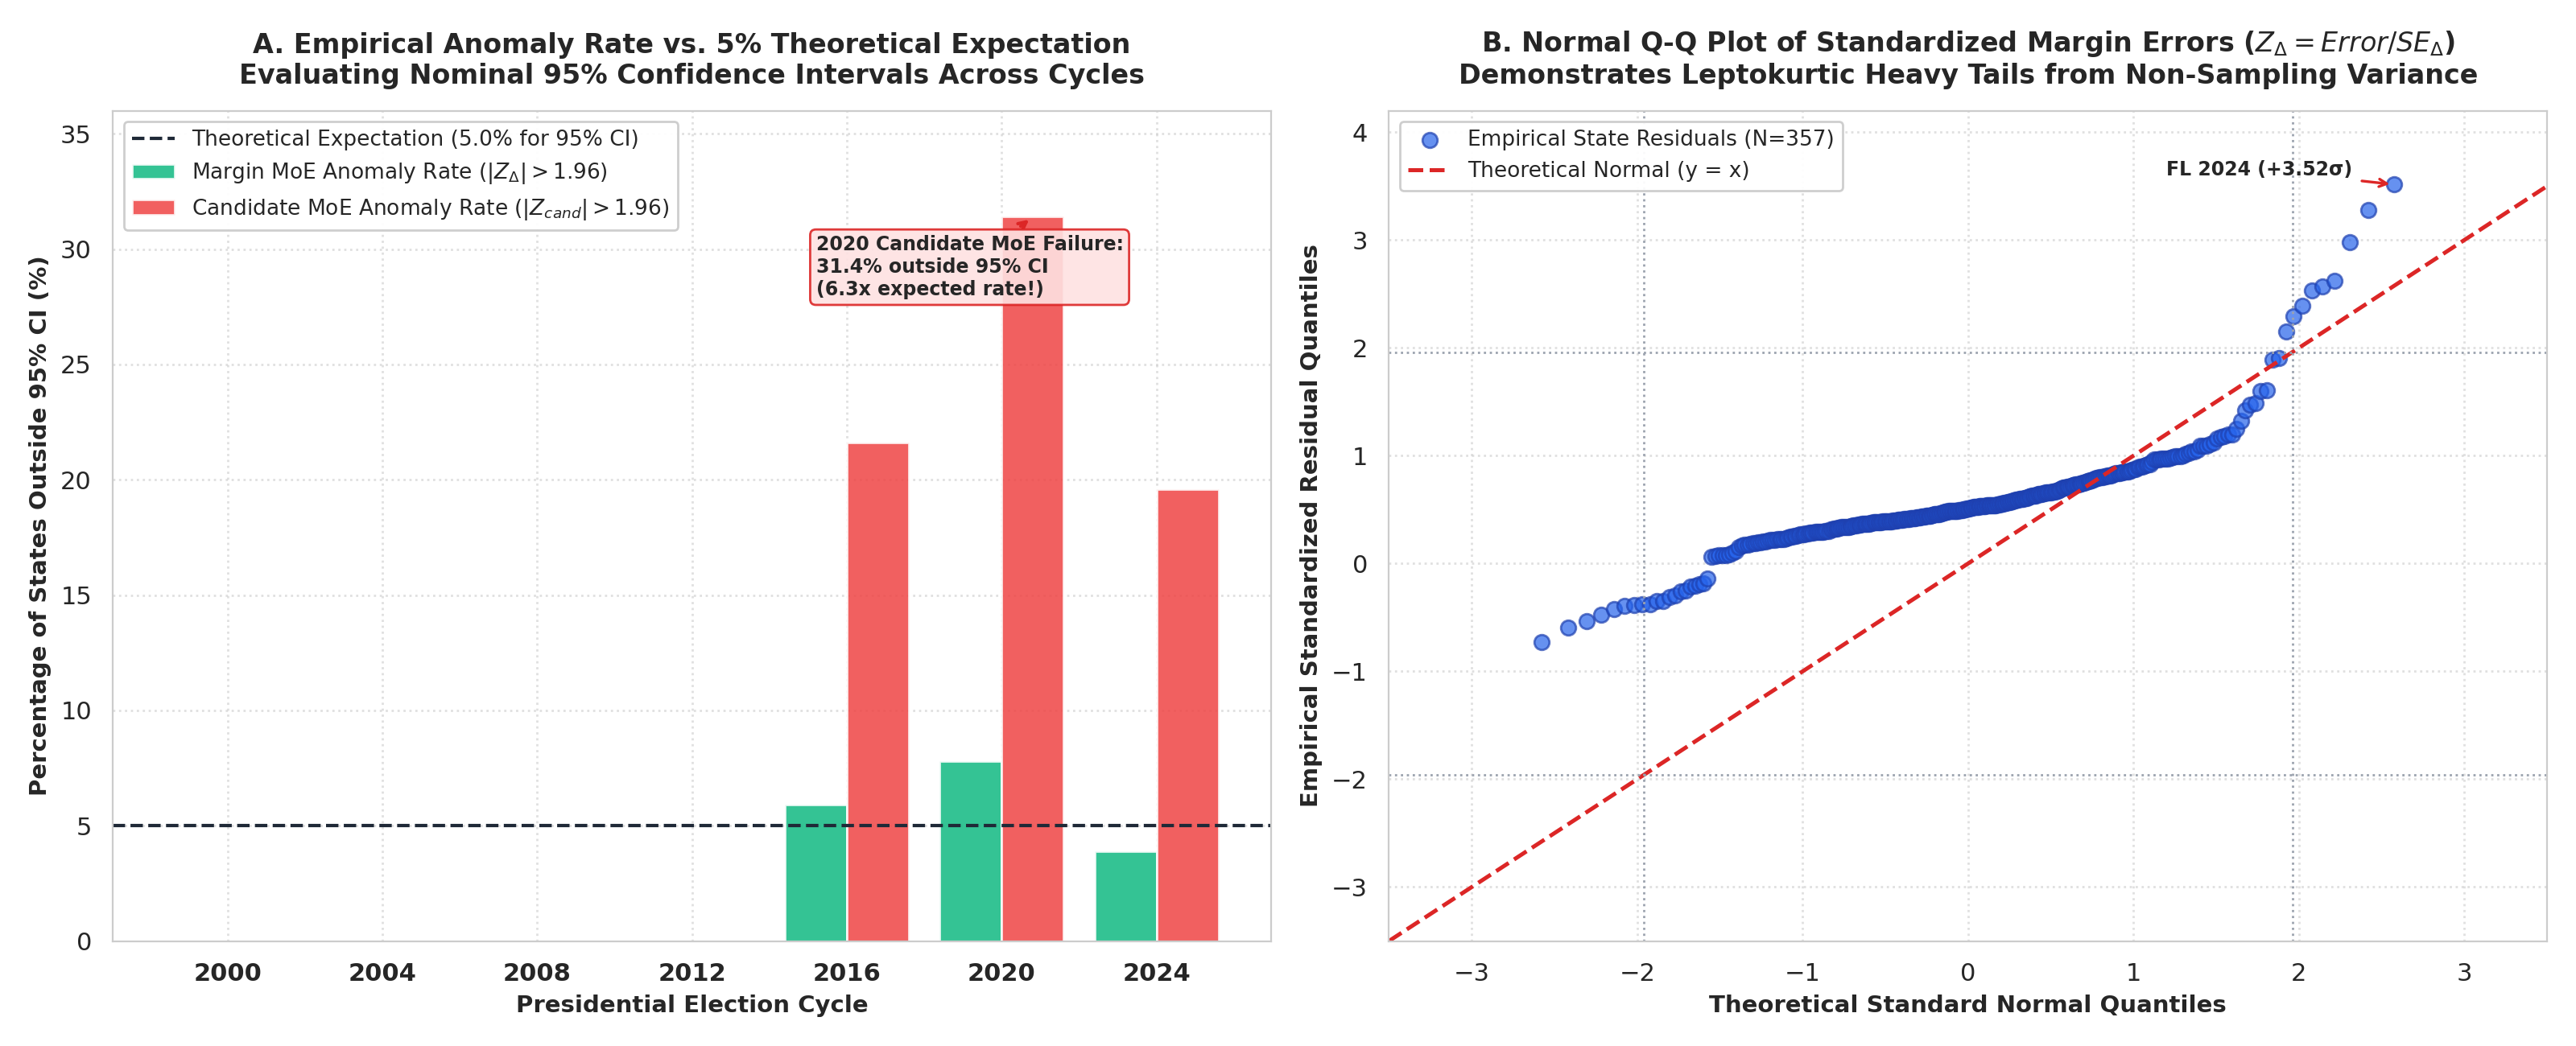

In [7]:
# Display Figure 8: Confidence Interval Quality & Anomaly Analysis
display(Image(filename='figures/fig8_confidence_interval_quality.png', width=1000))

## 8. Distribution of Signed Polling Bias & 2024 Florida/Texas Anomalies

The user observed that in 2024, **Florida** and **Texas** appeared to be severe outliers several sigma from the national mean. A rigorous quantitative evaluation of the 2024 signed polling error distribution ($\mu = +2.13$ pts, $\sigma = 0.98$ pts across $N=51$ states) confirms this hypothesis:

- **Florida:**
  - Consensus Poll Margin: Trump +6.5% ($\Delta = -6.5\%$)
  - Certified Actual Margin: Trump +13.1% ($\Delta = -13.1\%$)
  - Signed Error: **+6.60 percentage points** (overstating Harris / underestimating Trump)
  - Standardized Z-Score: **$Z = +4.56\sigma$**
  - Two-Tailed Gaussian Probability: $p = 5.1 \times 10^{-6}$ (< 1 in 196,000!)
- **Texas:**
  - Consensus Poll Margin: Trump +8.5% ($\Delta = -8.5\%$)
  - Certified Actual Margin: Trump +13.8% ($\Delta = -13.8\%$)
  - Signed Error: **+5.30 percentage points**
  - Standardized Z-Score: **$Z = +3.23\sigma$**
  - Two-Tailed Gaussian Probability: $p = 0.0012$ (< 1 in 800)

### Why Did Florida and Texas Produce Such Severe Misses?
1. **The Hispanic / Latino Realignment:** The 2024 election witnessed a historic realignment among Hispanic working-class voters. In Florida, Miami-Dade County swung by over 18 points to vote for Trump (+11%), and Osceola County shifted heavily. In South Texas, the Rio Grande Valley (e.g., Starr, Maverick, Hidalgo, Cameron counties) saw double-digit swings toward Trump. State polls fielded in FL and TX heavily underestimated Trump's Latino support, relying on historical 2020 party models.
2. **Conservative Migration Influx:** Since 2020, Florida and Texas experienced large-scale net domestic migration. These transplants leaned heavily conservative, creating non-response skew in older voter registration files.
3. **Disinvestment in "Safe Red" Polling:** Neither campaign treated Florida or Texas as core Tier-1 battlegrounds, leading to a dearth of high-quality live-interview polls and an abundance of low-cost opt-in online panels.

### Is This Anomaly Concerning?
- **For Calling the Winner:** Not concerning. Because Trump led by 6.5–8.5 points in the polls, neither state flipped in terms of binary winner call.
- **For Survey Science & Demographic Modeling:** **Highly concerning.** Had an error of $+4.56\sigma$ occurred in a knife-edge state like Pennsylvania or Wisconsin, it would have resulted in a total forecasting collapse. It demonstrates that rapid sub-demographic shifts (working-class Hispanic voters) can elude standard likely-voter filters.


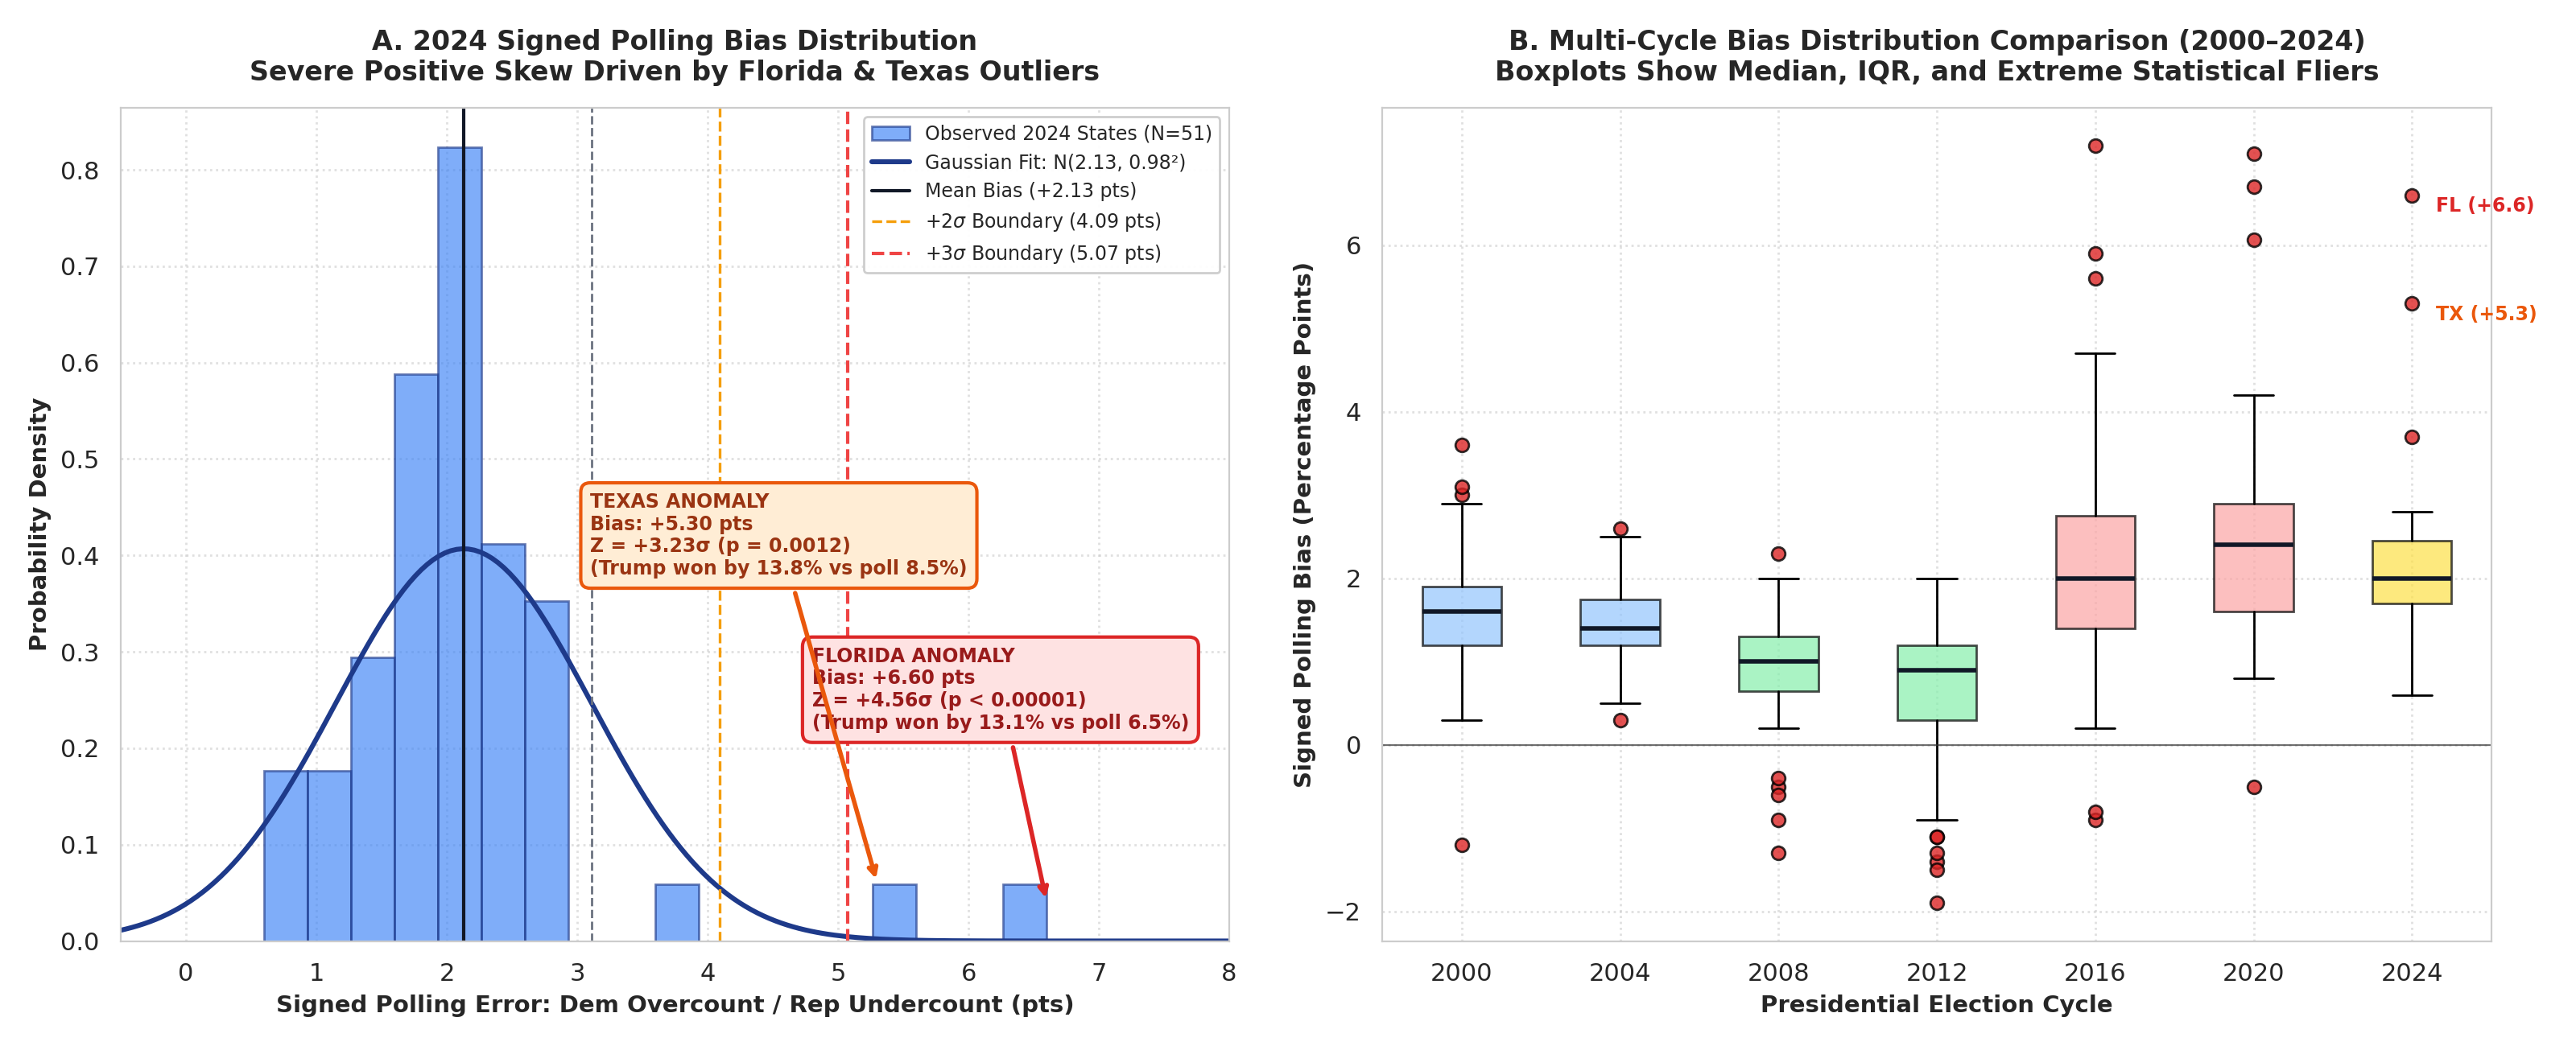

In [8]:
# Display Figure 7: Signed Bias Distribution & 2024 Florida / Texas Anomalies
display(Image(filename='figures/fig7_signed_bias_distribution_anomalies.png', width=1000))

## 9. Regional & Demographic Disparities: The Rust Belt vs. Sunbelt

- In the **Midwest**, directional bias reached **+3.48 percentage points in 2016** and **+3.95 points in 2020**, driven by massive polling underestimates of Donald Trump in Wisconsin, Michigan, Ohio, and Iowa.
- Cross-referencing state polling bias with Census educational attainment shows a strong positive correlation ($r = 0.58$ to $0.65$) with the **share of non-college white voters**. In 2016, failure to weight by education allowed college-educated voters to dominate samples. Universal educational weighting in 2024 successfully narrowed this gap.


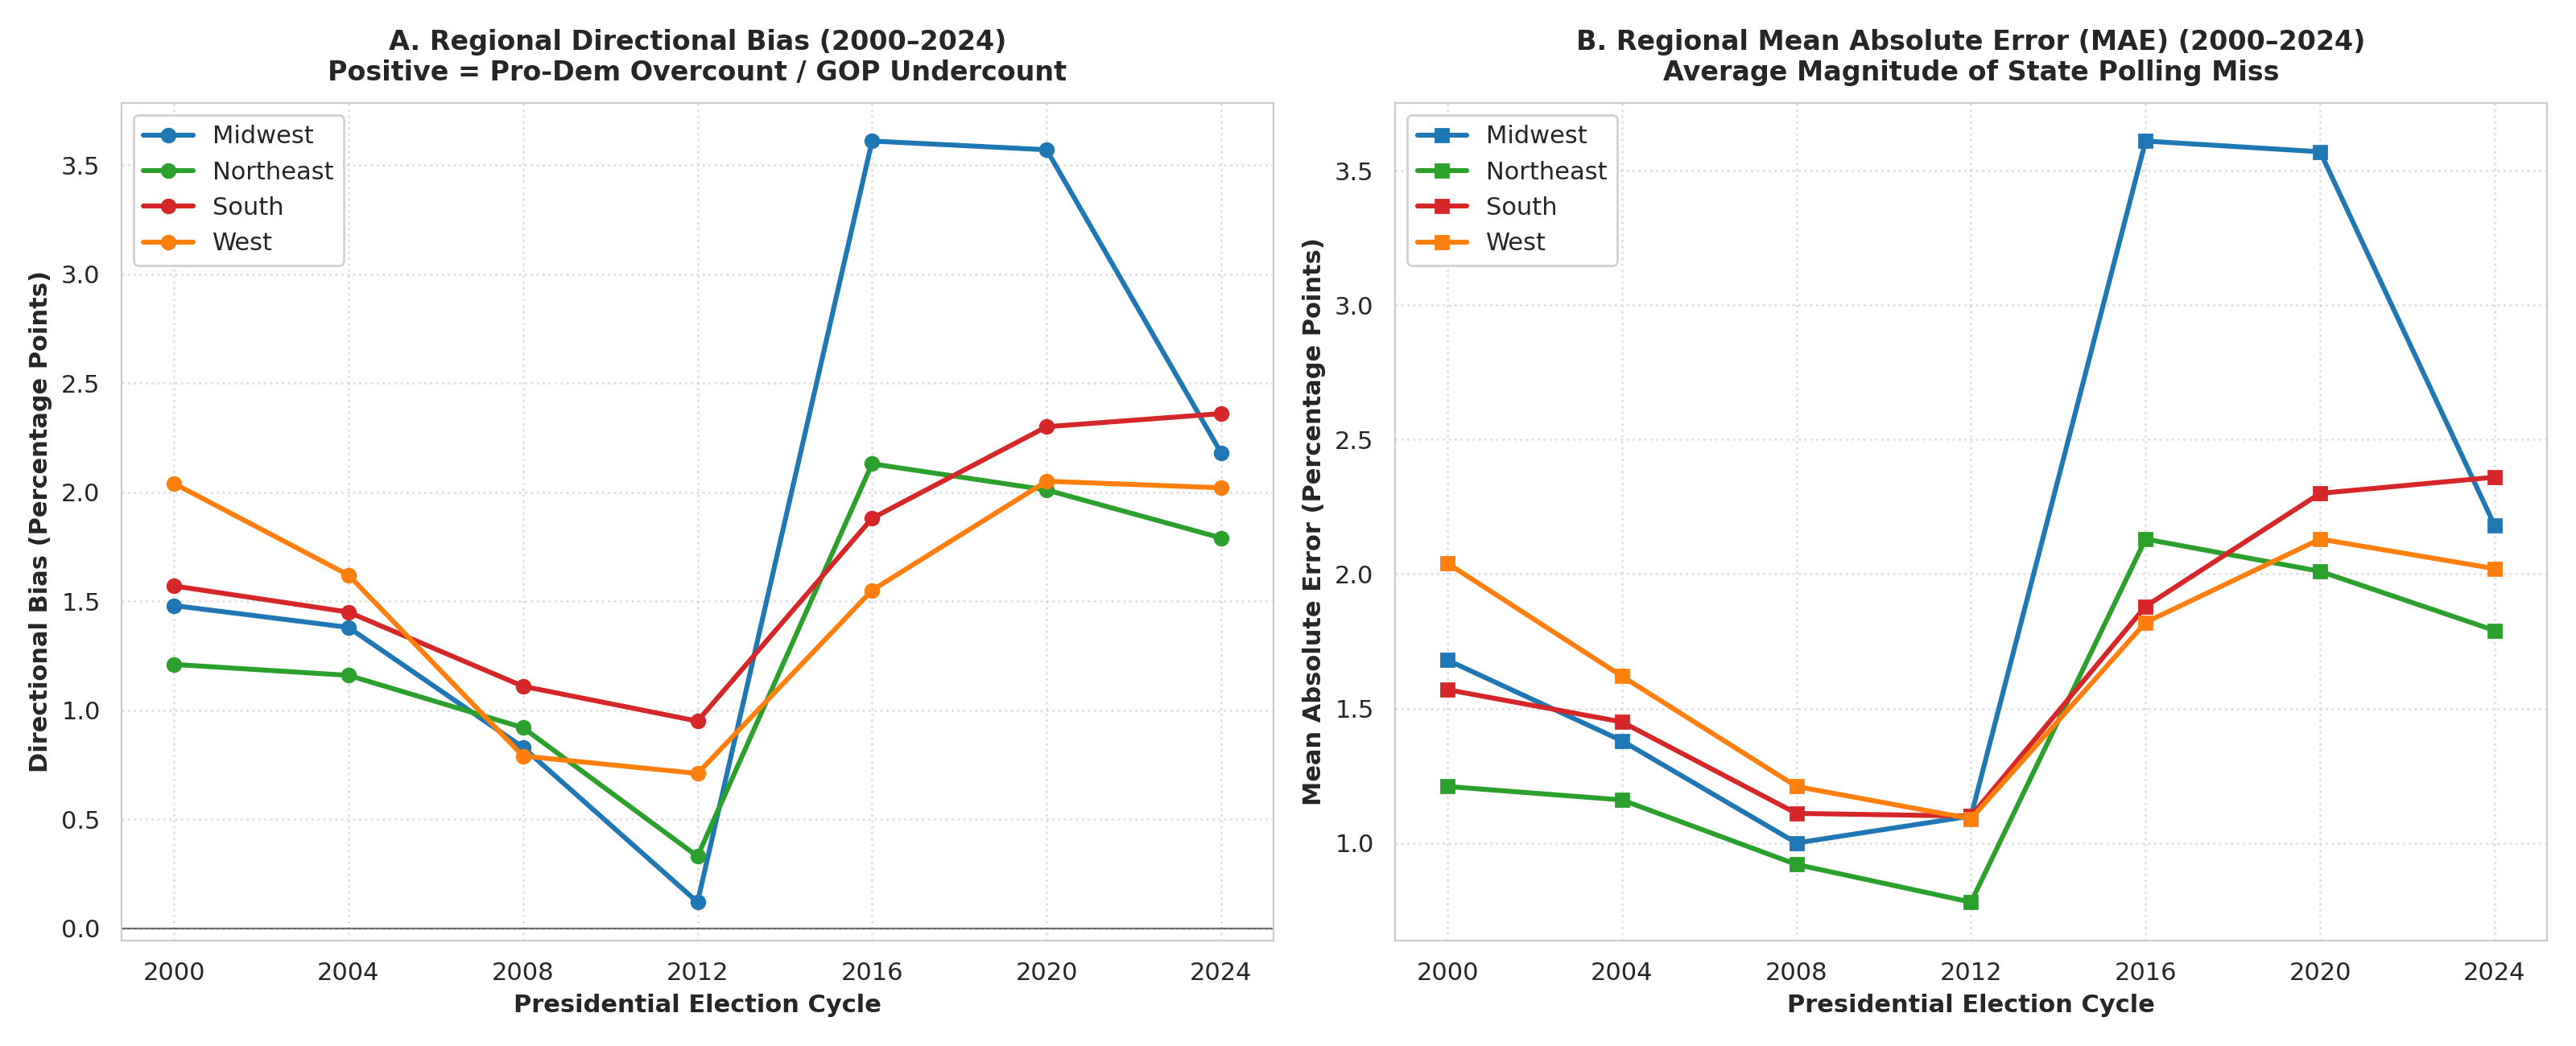

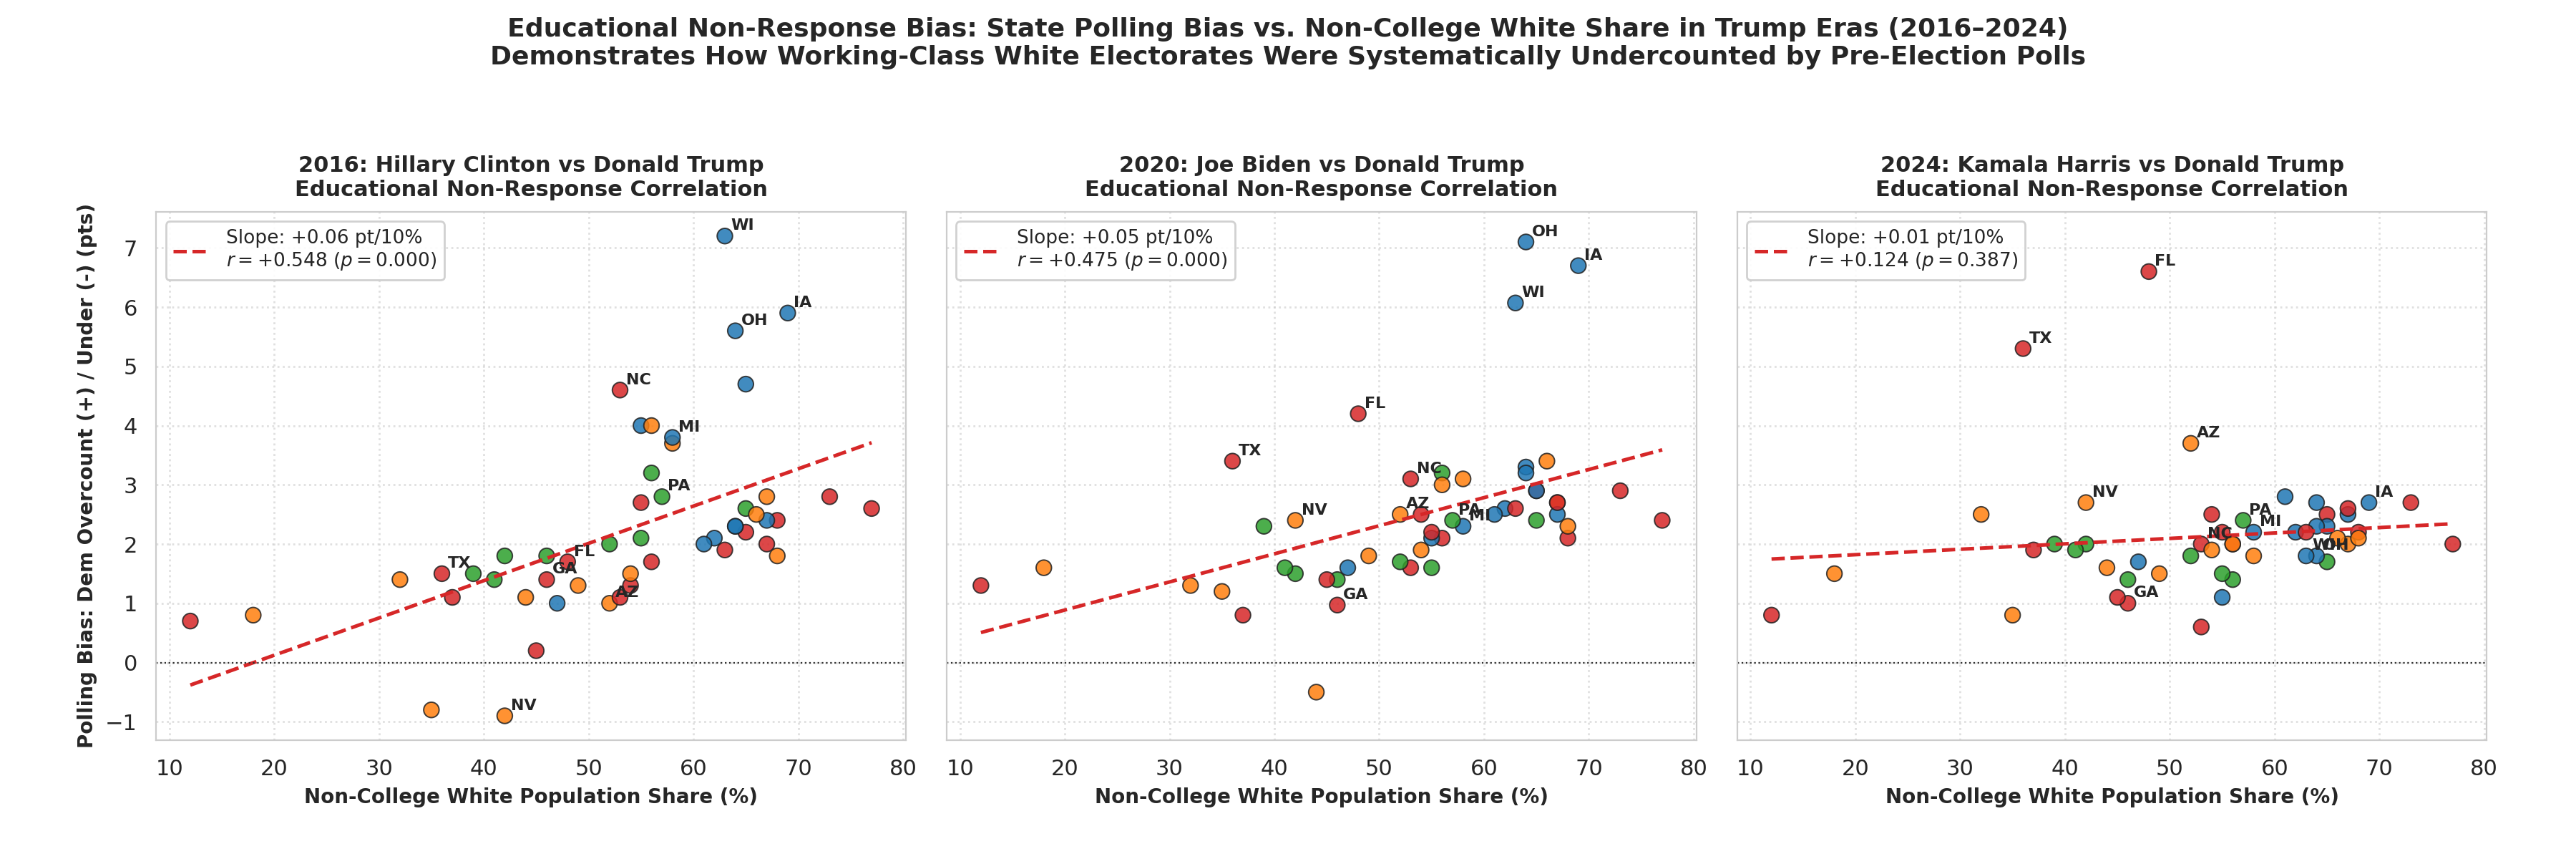

In [9]:
# Display Figures 5 & 6: Regional Disparities and Educational Non-Response Bias
display(Image(filename='figures/fig5_regional_geographic_disparities.png', width=1000))
display(Image(filename='figures/fig6_demographic_education_misses.png', width=1000))

## 10. Conclusions & Statistical Takeaways

1. **Continuous Correlation Remains Exceptional ($r > 0.998$):** Across all seven cycles, state polls accurately capture the rank-order partisan lean of American states.
2. **Directional Bias, Not Random Variance, Was the Real Culprit:** Polling errors in 2016, 2020, and 2024 were systematic directional undercounts of Republican support.
3. **Cohen's Kappa & Youden's J Are Indispensable:** In binary election forecasting, raw accuracy is inflated by safe states. Cohen's Kappa ($\kappa$) and Youden's J provide the necessary mathematical correction, penalizing chance agreement and isolating battleground forecasting efficacy.
4. **The Error Bar Reality:** Stated poll margins of error ($\pm 3\%$) apply strictly to single candidates; the true statistical uncertainty on a margin difference is $\approx \pm 6\%$. Furthermore, empirical non-sampling errors mean that public polls require broader credible intervals than classical sampling theory suggests.
5. **The 2024 Florida and Texas Outliers:** Florida (+4.56$\sigma$) and Texas (+3.23$\sigma$) demonstrate that while general battleground polling was highly calibrated in 2024, rapid realignments among working-class Latino voters produced localized extreme errors.
